# Лабораторная работа № 4. Кластеризация
М.А. Мотовилов, группа 4415, вариант 4. ГУАП, 2026.

Цель — изучить k-means и агломеративную кластеризацию на искусственных данных
и данных о кредитах. Выполнены обе обязательные части методички.
Вариант 4 принят по подтверждённому распределению в материалах ЛР3.
Дополнительные задания выдаются после защиты и в обязательный объём не входят.

Файл `bank_loan_default.csv` должен лежать рядом с ноутбуком (в Colab — загрузить
его в текущую папку). Зависимости: numpy, pandas, matplotlib, seaborn,
scipy, scikit-learn. Ячейки выполнять сверху вниз. Seed = 42.
Выходные файлы создаются в `utility/results` и `utility/figures`.

In [1]:
# 01. Импорт и вспомогательные функции
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, adjusted_rand_score, adjusted_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score,
    fowlkes_mallows_score)
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

SEED = 42
ROOT = Path.cwd()
RES, FIG = ROOT / 'utility/results', ROOT / 'utility/figures'
RES.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
def quality(X, labels, y=None):
    out = {'silhouette': silhouette_score(X, labels)}
    if y is not None:
        out.update(ARI=adjusted_rand_score(y, labels),
                   AMI=adjusted_mutual_info_score(y, labels),
                   FMI=fowlkes_mallows_score(y, labels),
                   homogeneity=homogeneity_score(y, labels),
                   completeness=completeness_score(y, labels),
                   V_measure=v_measure_score(y, labels))
    return out
print('Python', platform.python_version(), '| pandas', pd.__version__,
      '| sklearn', sklearn.__version__, '| scipy', scipy.__version__)

Python 3.14.9 | pandas 3.0.3 | sklearn 1.9.1 | scipy 1.18.1


## 1 Искусственные данные
### 1.1 Генерация и стандартизация
Функция сохранена из методички: три группы с центрами (3, 3), (6, 9), (9, 3),
разный масштаб осей. Выбрано n = 150 объектов в группе, всего 450.
StandardScaler вычитает среднее и делит на стандартное отклонение (ddof = 0).
Преобразование обучается на всей выборке: задача описательная, тестовая выборка
и прогноз будущих объектов здесь не требуются.

In [2]:
# 02. Генерация по методичке
def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3], [6, 9], [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2).reshape((-1, 2))
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]}, columns=['x', 'y'])
    return df.sample(frac=1.0)

synthetic = make_data(150, SEED)
synthetic_scaler = StandardScaler()
Xs = synthetic_scaler.fit_transform(synthetic)
display(Markdown('Первые пять объектов искусственной выборки в исходных координатах.'))
display(synthetic.head())
display(Markdown('Проверка стандартизации: средние близки к 0, стандартные отклонения равны 1.'))
display(pd.DataFrame({'среднее': Xs.mean(axis=0), 'стд. ddof=0': Xs.std(axis=0)},
                     index=synthetic.columns))
synthetic.to_csv(RES / 'synthetic.csv', index_label='source_row')

Первые пять объектов искусственной выборки в исходных координатах.

,x,y
371,138.5322,2.2047
103,43.9545,2.0162
259,130.2888,4.2895
432,188.1651,1.2553
385,194.2600,1.6171


Проверка стандартизации: средние близки к 0, стандартные отклонения равны 1.

,среднее,стд. ddof=0
x,1.1448e-16,1.0
y,-9.4739e-17,1.0


### 1.2 k-means для 2, 3 и 4 кластеров
Алгоритм минимизирует сумму квадратов расстояний до центров (inertia).
Используются k-means++, n_init = 20, random_state = 42.
На графиках показаны исходные единицы; центры возвращены из стандартизованного
пространства через inverse_transform. Метки кластеров — условные номера.

Разбиения при k = 2, 3 и 4; чёрные кресты — центры групп.

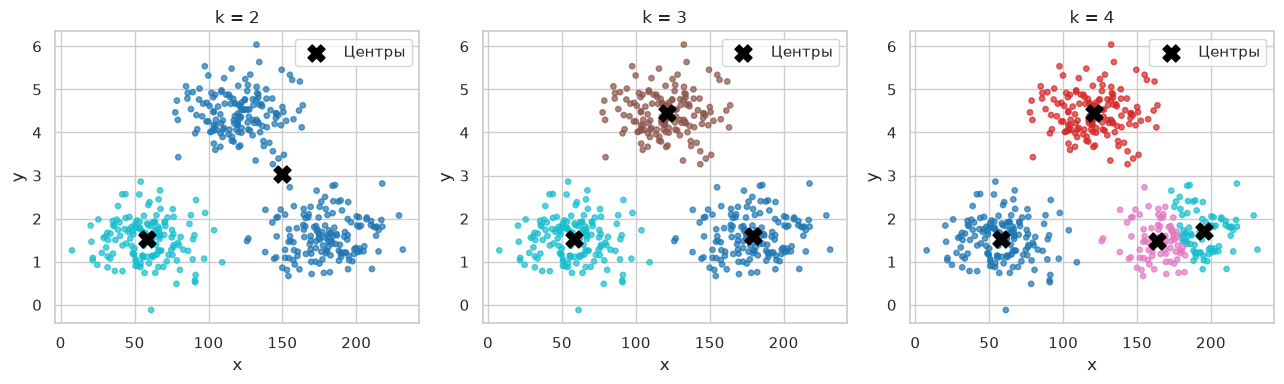

Качество трёх разбиений: чем выше силуэт, тем лучше отделены группы.

,k,inertia,silhouette
0,2,494.1837,0.4876
1,3,111.1488,0.7065
2,4,96.4855,0.5705


In [3]:
# 03. Разбиения и центры
synthetic_models = {}
rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, k in zip(axes, [2, 3, 4]):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = model.fit_predict(Xs)
    synthetic_models[k] = model
    rows.append({'k': k, 'inertia': model.inertia_, **quality(Xs, labels)})
    ax.scatter(synthetic.x, synthetic.y, c=labels, cmap='tab10', s=15, alpha=.7)
    centers = synthetic_scaler.inverse_transform(model.cluster_centers_)
    ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=150, label='Центры')
    ax.set(xlabel='x', ylabel='y', title=f'k = {k}')
    ax.legend()
display(Markdown('Разбиения при k = 2, 3 и 4; чёрные кресты — центры групп.'))
savefig('01_synthetic_clusters')
synthetic_metrics = pd.DataFrame(rows)
display(Markdown('Качество трёх разбиений: чем выше силуэт, тем лучше отделены группы.'))
display(synthetic_metrics)
synthetic_metrics.to_csv(RES / 'synthetic_metrics.csv', index=False)

### 1.3 Метод локтя
Для k от 1 до 10 считаем inertia; силуэт определён при k ≥ 2.
Inertia убывает при росте k сама по себе: нужен перегиб кривой и согласование
с силуэтом, а не минимальное значение inertia.

Выбор k: слева локоть inertia, справа силуэт. Предпочтительно k = 3.

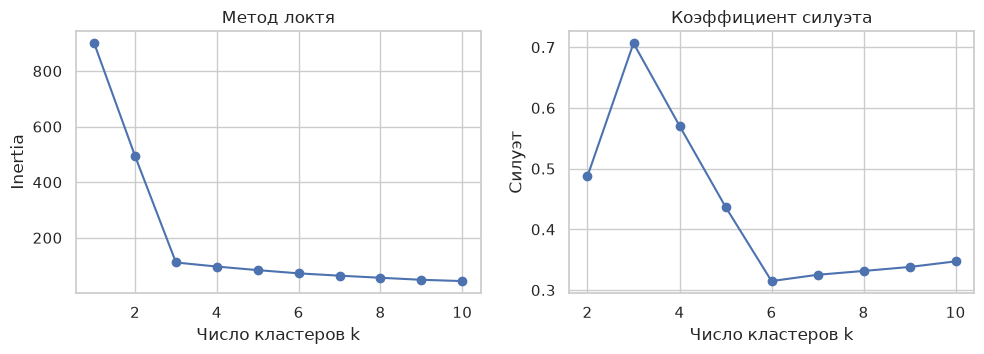

Численные результаты подбора k; при k = 1 силуэт не определён.

,k,inertia,silhouette
0,1,900.0000,NaN
1,2,494.1837,0.4876
2,3,111.1488,0.7065
3,4,96.4855,0.5705
4,5,83.6785,0.4371
5,6,72.0632,0.3148
6,7,63.7044,0.3252
7,8,56.2042,0.3315
8,9,48.9223,0.3381
9,10,44.2900,0.3473


Максимальный силуэт получен при **k = 3**. При k = 2 объединяются разные сгенерированные группы; при k = 4 одна из групп дробится. Кривая локтя позволяет проверить выбор k = 3.

In [4]:
# 04. Локоть и силуэт на искусственных данных
rows = []
for k in range(1, 11):
    m = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    rows.append({'k': k, 'inertia': m.inertia_,
                 'silhouette': silhouette_score(Xs, m.labels_) if k > 1 else np.nan})
synthetic_search = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
axes[0].plot(synthetic_search.k, synthetic_search.inertia, 'o-')
axes[0].set(xlabel='Число кластеров k', ylabel='Inertia', title='Метод локтя')
axes[1].plot(synthetic_search.k, synthetic_search.silhouette, 'o-')
axes[1].set(xlabel='Число кластеров k', ylabel='Силуэт', title='Коэффициент силуэта')
display(Markdown('Выбор k: слева локоть inertia, справа силуэт. Предпочтительно k = 3.'))
savefig('02_synthetic_selection')
display(Markdown('Численные результаты подбора k; при k = 1 силуэт не определён.'))
display(synthetic_search)
synthetic_search.to_csv(RES / 'synthetic_search.csv', index=False)
best_syn = int(synthetic_search.loc[synthetic_search.silhouette.idxmax(), 'k'])
display(Markdown(f'Максимальный силуэт получен при **k = {best_syn}**. '
    'При k = 2 объединяются разные сгенерированные группы; '
    'при k = 4 одна из групп дробится. Кривая локтя позволяет проверить выбор k = 3.'))

## 2 Кредитные данные, вариант 4
### 2.1 Загрузка и аудит
`bank_loan_default.csv`: возраст, годовой доход (USD), тип занятости, образование,
сумма кредита (USD), ставка (%), срок (месяцы), кредитный скор,
число открытых счетов, просрочка 30 дней и тип жилья.
`Default` — известный класс (1 — дефолт, 0 — нет), используется только для
цвета на исходных диаграммах, внешних метрик и интерпретации после обучения.
В матрицу признаков, стандартизацию и выбор k он не включается.

In [5]:
# 05. Загрузка и проверки
raw = pd.read_csv(ROOT / 'bank_loan_default.csv')
numeric = ['age', 'annual_income', 'loan_amount', 'interest_rate_pct',
           'term_months', 'credit_score', 'num_open_accounts']
categorical = ['employment_type', 'education', 'delinquency_30d', 'residence_type']
audit = pd.DataFrame({'тип': raw.dtypes.astype(str), 'пропуски': raw.isna().sum(),
                      'уникальных': raw.nunique()})
print('Размер:', raw.shape, '| Полных дубликатов:', raw.duplicated().sum())
display(Markdown('Первые пять строк кредитной выборки до обработки.'))
display(raw.head())
display(Markdown('Аудит столбцов: типы данных, число пропусков и уникальных значений.'))
display(audit)
display(Markdown('Описательная статистика числовых признаков в исходных единицах.'))
display(raw[numeric].describe().T)
assert set(raw.Default.unique()) <= {0, 1}
assert np.isfinite(raw[numeric].to_numpy()).all()
assert not raw.isna().any().any()
assert not raw.duplicated().any()
valid = (raw.age.between(18, 100) & (raw.annual_income > 0) &
         (raw.loan_amount > 0) & (raw.interest_rate_pct > 0) &
         raw.term_months.isin([24, 36, 48, 60, 72]) &
         raw.credit_score.between(300, 850) & (raw.num_open_accounts >= 0))
assert valid.all(), 'Найдены недопустимые значения: требуется проверка'
data = raw.copy()
y = data['Default'].copy()
X = data[numeric].copy()
audit.to_csv(RES / 'data_audit.csv', index_label='признак')
X.describe().T.to_csv(RES / 'descriptive.csv', index_label='признак')
print('Классы:', y.value_counts().sort_index().to_dict())
print('SHA256:', hashlib.sha256((ROOT / 'bank_loan_default.csv').read_bytes()).hexdigest())

Размер: (3041, 12) | Полных дубликатов: 0


Первые пять строк кредитной выборки до обработки.

,age,annual_income,employment_type,education,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts,delinquency_30d,residence_type,Default
0,42,57272.0,Self-Employed,Masters,8516.0,5.85,48,730.0,10,No,Own,0
1,51,45786.0,Salaried,Masters,13760.0,9.97,36,677.0,7,No,Mortgage,0
2,69,42359.0,Salaried,Bachelors,2569.0,13.75,48,624.0,2,No,Own,0
3,65,50709.0,Self-Employed,Masters,13204.0,8.70,48,698.0,3,No,Rent,0
4,30,46272.0,Salaried,HS,7700.0,7.53,48,532.0,7,No,Rent,0


Аудит столбцов: типы данных, число пропусков и уникальных значений.

,тип,пропуски,уникальных
age,int64,0,54
annual_income,float64,0,2939
employment_type,str,0,3
education,str,0,4
loan_amount,float64,0,2801
interest_rate_pct,float64,0,1214
term_months,int64,0,5
credit_score,float64,0,353
num_open_accounts,int64,0,15
delinquency_30d,str,0,2


Описательная статистика числовых признаков в исходных единицах.

,count,mean,std,min,25%,50%,75%,max
age,3041.0,47.0888,15.6001,21.0,34.00,47.0,60.00,74.000
annual_income,3041.0,45746.1828,23572.5062,7433.0,28741.00,40826.0,57428.00,237129.000
loan_amount,3041.0,10683.3093,7384.8668,1016.0,5540.00,8797.0,13464.00,69139.000
interest_rate_pct,3041.0,9.4363,3.5235,1.9,7.15,9.3,11.44,33.888
term_months,3041.0,47.6962,13.8832,24.0,36.00,48.0,60.00,72.000
credit_score,3041.0,681.2634,73.0071,417.0,632.00,683.0,733.00,850.000
num_open_accounts,3041.0,4.5459,2.1760,0.0,3.00,4.0,6.00,14.000


Классы: {0: 2421, 1: 620}
SHA256: ac9181e55be37a2436df8eff1a5fb3fe09c6bbb253540a1ff5e3ed4caf1c90af


### 2.2 Предобработка и исходные зависимости
Пропуски, дубликаты и допустимость значений проверены явными утверждениями.
Если проверки не проходят на другом файле, выполнение остановится для анализа.
Большие доходы и суммы кредитов сохранены: нет оснований считать их ошибками.
IQR используется для диагностики, а не для автоматического удаления клиентов.
Базовая кластеризация использует 7 числовых признаков; срок кредита трактуется
как длительность. Четыре категориальных признака сохранены для описания групп,
их кодирование относится к дополнительным заданиям 1–2 методички.
Матрица рассеяния содержит все 7 числовых признаков и все объекты.

Число значений за IQR-границами; это диагностика, строки не удаляются.

,Число значений вне IQR-границ
age,0
annual_income,93
loan_amount,153
interest_rate_pct,41
term_months,0
credit_score,11
num_open_accounts,29


Попарные связи признаков; цвет — Default, который не входит в обучение.

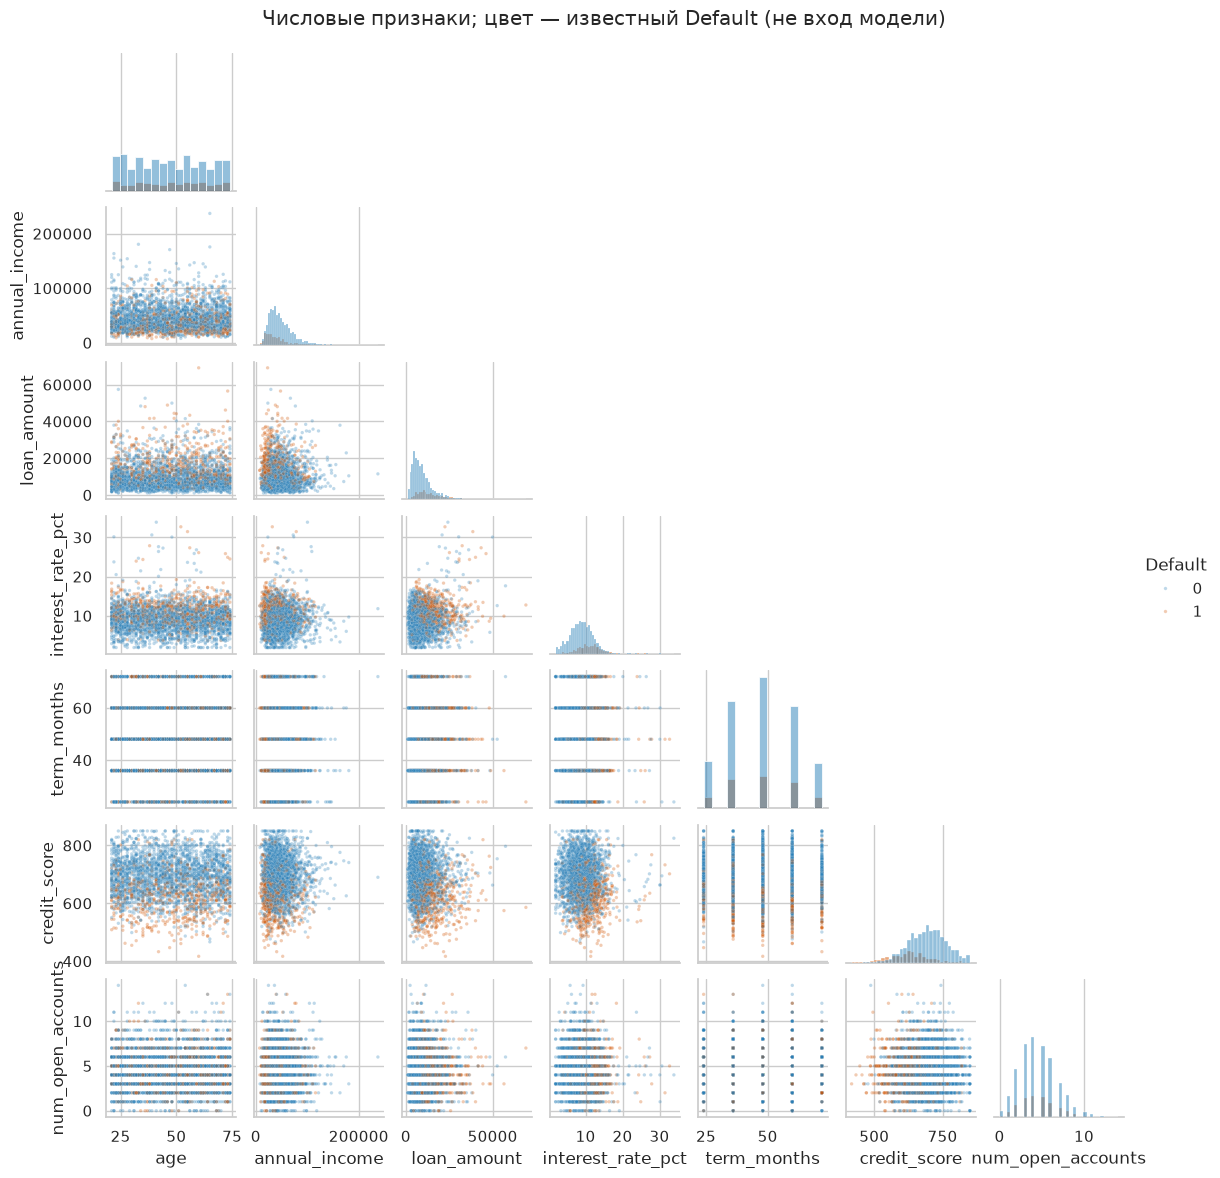

In [6]:
# 06. Матрица рассеяния и диагностика распределений
q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
outlier_counts = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum()
display(Markdown('Число значений за IQR-границами; это диагностика, строки не удаляются.'))
display(outlier_counts.rename('Число значений вне IQR-границ').to_frame())
outlier_counts.to_csv(RES / 'iqr_diagnostics.csv', index_label='признак')
display(Markdown('Попарные связи признаков; цвет — Default, который не входит в обучение.'))
g = sns.pairplot(data[numeric + ['Default']], hue='Default',
                 vars=numeric, diag_kind='hist', corner=True,
                 plot_kws={'s': 6, 'alpha': .3, 'rasterized': True}, height=1.65,
                 palette={0: '#2980b9', 1: '#d35400'})
g.fig.suptitle('Числовые признаки; цвет — известный Default (не вход модели)', y=1.02)
g.savefig(FIG / '03_pairplot.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.3 Стандартизация и выбор k для k-means
Масштабирование обязательно из-за различия единиц (USD, месяцы, проценты).
StandardScaler обучается только на X. Сравниваются k = 2…10; k = 1 нужен
для локтя. Основной критерий — максимум внутреннего силуэта. Внешние метрики и доля дефолта не используются для выбора.
Силуэт вычисляется точно на всех объектах, без случайной подвыборки.

Проверка StandardScaler для семи числовых признаков.

,среднее,стд. ddof=0
age,9.3462e-18,1.0
annual_income,-4.9652e-17,1.0
loan_amount,5.1404e-17,1.0
interest_rate_pct,2.1029e-17,1.0
term_months,7.3601e-17,1.0
credit_score,-4.8366e-16,1.0
num_open_accounts,1.0281e-16,1.0


Метрики k-means для разных k; число групп выбирается по максимуму силуэта.

,k,inertia,silhouette
0,1,21287.0000,NaN
1,2,18973.3235,0.1178
2,3,17159.1392,0.1184
3,4,15864.0020,0.1168
4,5,14815.5388,0.1108
5,6,13972.8236,0.1086
6,7,13229.2231,0.1105
7,8,12719.6119,0.1161
8,9,12210.9940,0.1111
9,10,11792.6616,0.1105


Выбранное k: 3


Локоть и силуэт на кредитах: результаты для k = 2 и k = 3 очень близки.

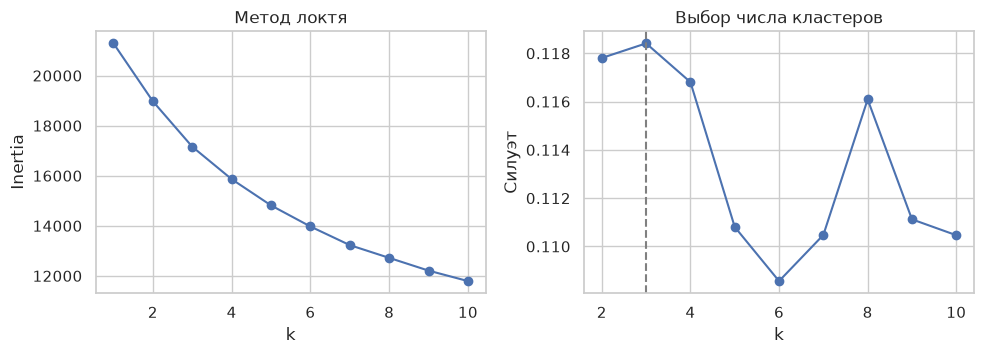

In [7]:
# 07. StandardScaler и подбор k
scaler = StandardScaler()
Z = scaler.fit_transform(X)
assert 'Default' not in X.columns and X.shape[1] == 7
assert np.allclose(Z.mean(axis=0), 0, atol=1e-10)
assert np.allclose(Z.std(axis=0), 1, atol=1e-10)
scale_check = pd.DataFrame({'среднее': Z.mean(axis=0), 'стд. ddof=0': Z.std(axis=0)}, index=numeric)
display(Markdown('Проверка StandardScaler для семи числовых признаков.'))
display(scale_check)
scale_check.to_csv(RES / 'scale_check.csv', index_label='признак')
models, rows = {}, []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    models[k] = model
    rows.append({'k': k, 'inertia': model.inertia_,
                 **(quality(Z, model.labels_) if k > 1 else {})})
search = pd.DataFrame(rows)
best_k = int(search.loc[search.silhouette.idxmax(), 'k'])
km = models[best_k]
labels_km = km.labels_
display(Markdown('Метрики k-means для разных k; число групп выбирается по максимуму силуэта.'))
display(search)
print('Выбранное k:', best_k)
search.to_csv(RES / 'kmeans_search.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
axes[0].plot(search.k, search.inertia, 'o-')
axes[0].set(xlabel='k', ylabel='Inertia', title='Метод локтя')
axes[1].plot(search.k, search.silhouette, 'o-')
axes[1].axvline(best_k, color='grey', linestyle='--')
axes[1].set(xlabel='k', ylabel='Силуэт', title='Выбор числа кластеров')
display(Markdown('Локоть и силуэт на кредитах: результаты для k = 2 и k = 3 очень близки.'))
savefig('04_bank_selection')

### 2.4 Состав кластеров и средние показатели
Средние рассчитаны в исходных единицах по всем числовым признакам.
Для категорий математическое среднее не определено: приведены моды и
полные доли категорий. `default_rate` — характеристика уже полученных групп,
а не вход обучения. В `assignments.csv` сохранены исходные строки и номера
обоих кластеров, чтобы можно было найти любой объект.

Размеры групп: n — число клиентов, default_rate — доля дефолтов от 0 до 1.

,n,default_rate
cluster,,
0,509,0.5756
1,1319,0.1274
2,1213,0.1311


Средние числовые признаки каждой группы в исходных единицах.

,age,annual_income,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts
cluster,,,,,,,
0,48.3752,42317.2436,22285.1686,11.8035,47.3399,631.1041,4.1866
1,33.5375,46435.3518,8274.9748,9.1214,47.4632,694.4913,4.5042
2,61.2844,46435.6439,8433.7189,8.7853,48.0989,687.9275,4.7420


Наиболее частые значения категориальных признаков в каждой группе.

,employment_type,education,delinquency_30d,residence_type
cluster,,,,
0,Salaried,Bachelors,No,Rent
1,Salaried,Bachelors,No,Rent
2,Salaried,Bachelors,No,Rent


Центры k-means: отклонения от общего среднего в стандартных отклонениях.

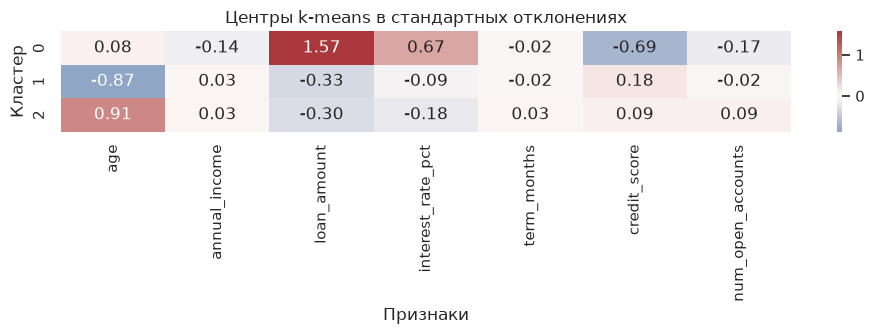

**Интерпретация кластеров k-means:**

- Кластер 0: n=509, доля дефолта 57.6%. Основные отличия: loan_amount: 22285.17 (+1.57 σ); credit_score: 631.10 (-0.69 σ); interest_rate_pct: 11.80 (+0.67 σ).

- Кластер 1: n=1319, доля дефолта 12.7%. Основные отличия: age: 33.54 (-0.87 σ); loan_amount: 8274.97 (-0.33 σ); credit_score: 694.49 (+0.18 σ).

- Кластер 2: n=1213, доля дефолта 13.1%. Основные отличия: age: 61.28 (+0.91 σ); loan_amount: 8433.72 (-0.30 σ); interest_rate_pct: 8.79 (-0.18 σ).

In [8]:
# 08. Профили k-means
def profile(labels, prefix):
    frame = data.assign(cluster=labels)
    means = frame.groupby('cluster')[numeric].mean()
    sizes = frame.groupby('cluster').agg(n=('Default', 'size'), default_rate=('Default', 'mean'))
    modes = frame.groupby('cluster')[categorical].agg(lambda s: s.mode().iloc[0])
    means.to_csv(RES / f'{prefix}_means.csv')
    sizes.to_csv(RES / f'{prefix}_sizes.csv')
    modes.to_csv(RES / f'{prefix}_modes.csv')
    for col in categorical:
        pd.crosstab(frame.cluster, frame[col], normalize='index').to_csv(RES / f'{prefix}_{col}_shares.csv')
    display(Markdown('Размеры групп: n — число клиентов, default_rate — доля дефолтов от 0 до 1.'))
    display(sizes)
    display(Markdown('Средние числовые признаки каждой группы в исходных единицах.'))
    display(means)
    display(Markdown('Наиболее частые значения категориальных признаков в каждой группе.'))
    display(modes)
    return means, sizes
km_means, km_sizes = profile(labels_km, 'kmeans')
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(pd.DataFrame(km.cluster_centers_, columns=numeric), annot=True,
            fmt='.2f', cmap='vlag', center=0, ax=ax)
ax.set(xlabel='Признаки', ylabel='Кластер', title='Центры k-means в стандартных отклонениях')
display(Markdown('Центры k-means: отклонения от общего среднего в стандартных отклонениях.'))
savefig('05_kmeans_profiles')
display(Markdown('**Интерпретация кластеров k-means:**'))
for cluster in km_means.index:
    deviations = (km_means.loc[cluster] - X.mean()) / X.std(ddof=0)
    strong = deviations.abs().nlargest(3).index
    text = '; '.join(f'{c}: {km_means.loc[cluster,c]:.2f} ({deviations[c]:+.2f} σ)' for c in strong)
    display(Markdown(f'- Кластер {cluster}: n={km_sizes.loc[cluster,"n"]:.0f}, '
        f'доля дефолта {km_sizes.loc[cluster,"default_rate"]:.1%}. Основные отличия: {text}.'))

### 2.5 Иерархическая агломеративная кластеризация
Используется евклидово расстояние и критерий Ward, минимизирующий прирост
внутрикластерной суммы квадратов. Дендрограмма строится по всем 3041 объектам;
для читаемости показаны последние 30 ветвей (число в скобках — размер ветви).
Для k = 2…10 разрезаем одно и то же полное дерево и выбираем максимум силуэта.
Затем отдельно обучаем AgglomerativeClustering с выбранным k и проверяем
совпадение разбиений через ARI = 1 (номера меток могут различаться).

Метрики разрезов дерева Ward; максимальный силуэт получен при k = 2.

,k,silhouette
0,2,0.1890
1,3,0.0767
2,4,0.0772
3,5,0.0513
4,6,0.0390
5,7,0.0382
6,8,0.0446
7,9,0.0485
8,10,0.0495


Ward: выбрано k = 2 | ARI двух реализаций = 1.0


Дерево по всем 3041 клиентам: показаны последние 30 ветвей и разрез на две группы.

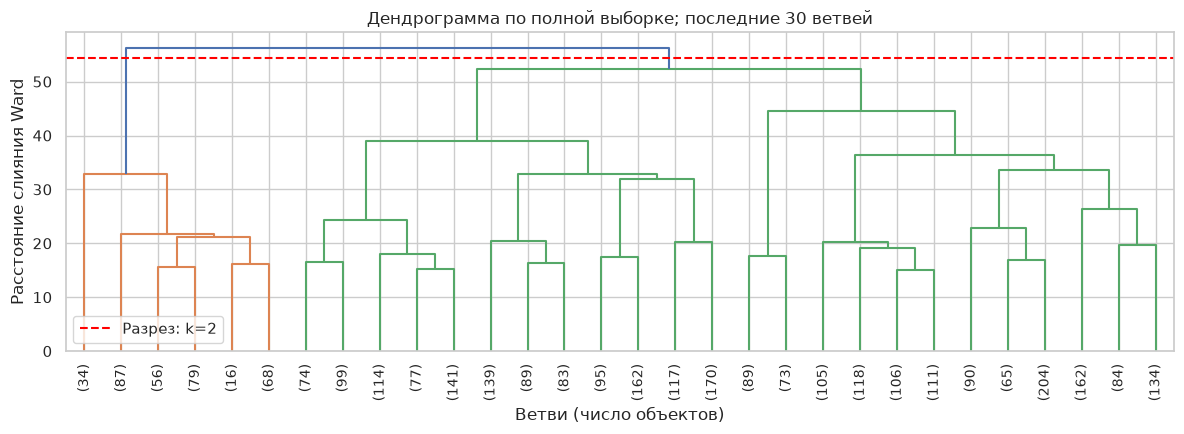

Размеры групп: n — число клиентов, default_rate — доля дефолтов от 0 до 1.

,n,default_rate
cluster,,
0,2701,0.1699
1,340,0.4735


Средние числовые признаки каждой группы в исходных единицах.

,age,annual_income,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts
cluster,,,,,,,
0,47.1055,45617.0111,8934.4499,9.1665,48.0133,685.0855,4.5020
1,46.9559,46772.3382,24576.4541,11.5793,45.1765,650.9000,4.8941


Наиболее частые значения категориальных признаков в каждой группе.

,employment_type,education,delinquency_30d,residence_type
cluster,,,,
0,Salaried,Bachelors,No,Rent
1,Salaried,Bachelors,No,Rent


**Интерпретация кластеров Ward:**

- Кластер 0: n=2701, доля дефолта 17.0%. Основные отличия: loan_amount: 8934.45 (-0.24 σ); interest_rate_pct: 9.17 (-0.08 σ); credit_score: 685.09 (+0.05 σ).

- Кластер 1: n=340, доля дефолта 47.4%. Основные отличия: loan_amount: 24576.45 (+1.88 σ); interest_rate_pct: 11.58 (+0.61 σ); credit_score: 650.90 (-0.42 σ).

In [9]:
# 09. Полное дерево Ward, дендрограмма и подбор k
tree = linkage(Z, method='ward', metric='euclidean')
rows = []
for k in range(2, 11):
    lab = cut_tree(tree, n_clusters=k).ravel()
    rows.append({'k': k, **quality(Z, lab)})
ward_search = pd.DataFrame(rows)
best_ward_k = int(ward_search.loc[ward_search.silhouette.idxmax(), 'k'])
ward = AgglomerativeClustering(n_clusters=best_ward_k, linkage='ward', metric='euclidean')
labels_ward = ward.fit_predict(Z)
tree_agreement = adjusted_rand_score(labels_ward, cut_tree(tree, n_clusters=best_ward_k).ravel())
assert np.isclose(tree_agreement, 1)
display(Markdown('Метрики разрезов дерева Ward; максимальный силуэт получен при k = 2.'))
display(ward_search)
print('Ward: выбрано k =', best_ward_k, '| ARI двух реализаций =', tree_agreement)
ward_search.to_csv(RES / 'ward_search.csv', index=False)
cut_height = (tree[-best_ward_k, 2] + tree[-best_ward_k + 1, 2]) / 2
fig, ax = plt.subplots(figsize=(12, 4.5))
dendrogram(tree, truncate_mode='lastp', p=30, leaf_rotation=90,
           color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, linestyle='--', color='red', label=f'Разрез: k={best_ward_k}')
ax.set(xlabel='Ветви (число объектов)', ylabel='Расстояние слияния Ward',
       title='Дендрограмма по полной выборке; последние 30 ветвей')
ax.legend()
display(Markdown('Дерево по всем 3041 клиентам: показаны последние 30 ветвей и разрез на две группы.'))
savefig('06_dendrogram')
ward_means, ward_sizes = profile(labels_ward, 'ward')
display(Markdown('**Интерпретация кластеров Ward:**'))
for cluster in ward_means.index:
    deviations = (ward_means.loc[cluster] - X.mean()) / X.std(ddof=0)
    strong = deviations.abs().nlargest(3).index
    text = '; '.join(f'{c}: {ward_means.loc[cluster,c]:.2f} ({deviations[c]:+.2f} σ)' for c in strong)
    display(Markdown(f'- Кластер {cluster}: n={ward_sizes.loc[cluster,"n"]:.0f}, '
        f'доля дефолта {ward_sizes.loc[cluster,"default_rate"]:.1%}. Основные отличия: {text}.'))

### 2.6 Метрики и сравнение
Силуэт (−1…1): больше — лучше.
ARI и AMI корректируются на случайные совпадения (могут быть отрицательными).
FMI, однородность, полнота и V-мера лежат в [0, 1], больше — лучше.
Внешние метрики сравнивают кластеры с Default, но цель кластеризации —
сходство клиентов, а не воспроизведение известных классов.
При разных k и несбалансированных классах отдельные метрики могут расходиться.

### Сравнение выбранных разбиений
В таблице сравниваются k-means при k = 3 и Ward при k = 2. **Silhouette: больше — лучше.** ARI, AMI, FMI, homogeneity, completeness и V_measure сравнивают кластеры с известным Default, который не участвовал в обучении.

метод,k-means,Ward
k,3.0000,2.0000
silhouette,0.1184,0.1890
ARI,0.1104,0.1590
AMI,0.0926,0.0547
FMI,0.5629,0.7782
homogeneity,0.1410,0.0466
completeness,0.0693,0.0673
V_measure,0.0930,0.0551


### Кластеры в двух проекциях признаков
**Верхний ряд — k-means, нижний — Ward.** Слева показаны годовой доход и сумма кредита, справа — кредитный скор и процентная ставка. Цвет обозначает кластер, а чёрные кресты — средние значения признаков в каждой группе. Номера и цвета кластеров условны: одинаковый цвет у разных методов не гарантирует одинаковый состав группы. Это двумерные проекции разбиений, построенных по семи стандартизованным признакам; оси показаны в исходных единицах. Перекрытие точек в проекции возможно.

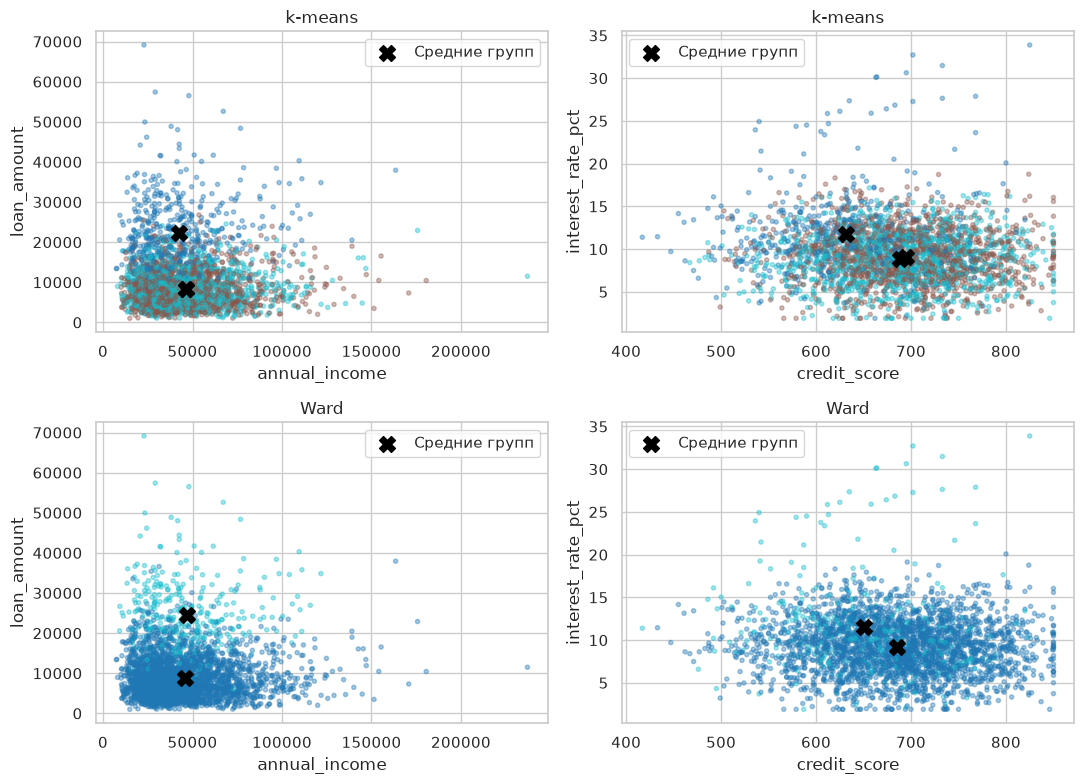

### Как качество зависит от числа кластеров
График показывает **силуэт** двух методов при изменении k. Кружки соответствуют k-means, квадраты — Ward. Для силуэта предпочтительны высокие значения. Число кластеров выбиралось по максимуму силуэта: k = 3 для k-means и k = 2 для Ward. Силуэт Ward равен 0,1890, k-means — 0,1184. У k-means при k = 2 значение почти такое же — 0,1178, поэтому выбор трёх групп неоднозначен. Ward предпочтителен по силуэту, но AMI и V-мера выше у k-means: общего превосходства по всем метрикам нет.

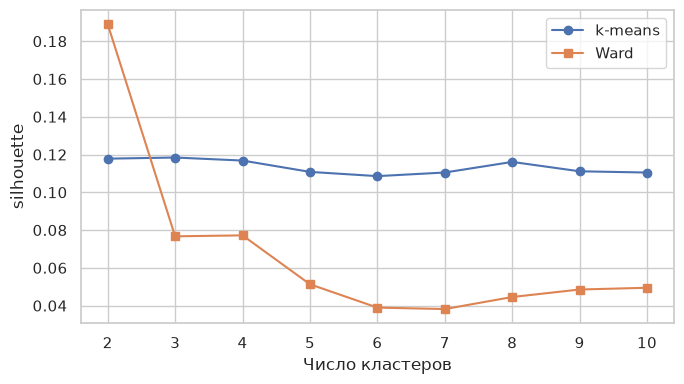

ARI между k-means и Ward: 0.14862333202980282


In [10]:
# 10. Итоговые метрики, объекты кластеров и две пары признаков
comparison = pd.DataFrame([
    {'метод': 'k-means', 'k': best_k, **quality(Z, labels_km, y)},
    {'метод': 'Ward', 'k': best_ward_k, **quality(Z, labels_ward, y)}
]).set_index('метод')
display(Markdown('### Сравнение выбранных разбиений\nВ таблице сравниваются k-means при k = 3 и Ward при k = 2. **Silhouette: больше — лучше.** ARI, AMI, FMI, homogeneity, completeness и V_measure сравнивают кластеры с известным Default, который не участвовал в обучении.'))
display(comparison.T)
comparison.to_csv(RES / 'comparison.csv')
assignments = data.assign(cluster_kmeans=labels_km, cluster_ward=labels_ward)
assignments.to_csv(RES / 'assignments.csv', index_label='source_row_0based')
for name, labels in [('kmeans', labels_km), ('ward', labels_ward)]:
    pd.crosstab(y, labels).to_csv(RES / f'{name}_contingency.csv')
display(Markdown('### Кластеры в двух проекциях признаков\n**Верхний ряд — k-means, нижний — Ward.** Слева показаны годовой доход и сумма кредита, справа — кредитный скор и процентная ставка. Цвет обозначает кластер, а чёрные кресты — средние значения признаков в каждой группе. Номера и цвета кластеров условны: одинаковый цвет у разных методов не гарантирует одинаковый состав группы. Это двумерные проекции разбиений, построенных по семи стандартизованным признакам; оси показаны в исходных единицах. Перекрытие точек в проекции возможно.'))
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, (method, labels) in enumerate([('k-means', labels_km), ('Ward', labels_ward)]):
    for col, (a, b) in enumerate([('annual_income', 'loan_amount'), ('credit_score', 'interest_rate_pct')]):
        ax = axes[row, col]
        ax.scatter(X[a], X[b], c=labels, cmap='tab10', s=9, alpha=.4)
        centers = data.assign(cluster=labels).groupby('cluster')[numeric].mean()
        ax.scatter(centers[a], centers[b], marker='X', c='black', s=130, label='Средние групп')
        ax.set(xlabel=a, ylabel=b, title=method)
        ax.legend()
savefig('07_bank_clusters')
display(Markdown('### Как качество зависит от числа кластеров\nГрафик показывает **силуэт** двух методов при изменении k. Кружки соответствуют k-means, квадраты — Ward. Для силуэта предпочтительны высокие значения. Число кластеров выбиралось по максимуму силуэта: k = 3 для k-means и k = 2 для Ward. Силуэт Ward равен 0,1890, k-means — 0,1184. У k-means при k = 2 значение почти такое же — 0,1178, поэтому выбор трёх групп неоднозначен. Ward предпочтителен по силуэту, но AMI и V-мера выше у k-means: общего превосходства по всем метрикам нет.'))
fig, axes = plt.subplots(1, 1, figsize=(7, 4))
for ax, col in [(axes, 'silhouette')]:
    ax.plot(search.k, search[col], 'o-', label='k-means')
    ax.plot(ward_search.k, ward_search[col], 's-', label='Ward')
    ax.set(xlabel='Число кластеров', ylabel=col)
    ax.legend()
savefig('08_method_selection')
summary = {'n': len(data), 'features': numeric, 'categorical': categorical,
           'best_synthetic_k': best_syn, 'best_k': best_k, 'best_ward_k': best_ward_k,
           'tree_agreement': tree_agreement,
           'cluster_agreement': adjusted_rand_score(labels_km, labels_ward),
           'default_rate': float(y.mean()),
           'sha256': hashlib.sha256((ROOT / 'bank_loan_default.csv').read_bytes()).hexdigest()}
(RES / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('ARI между k-means и Ward:', summary['cluster_agreement'])

## 3 Заключение

In [11]:
# 11. Выводы по фактически рассчитанным результатам
preferred = comparison.silhouette.idxmax()
other = comparison.silhouette.idxmin()
conclusions = [
    f'Выполнены обе части работы. Искусственная выборка содержит 450 объектов; '
    f'по силуэту выбрано k={best_syn}. В кредитной выборке {len(data)} заёмщик, '
    '7 числовых признаков. Пропуски, полные дубликаты и недопустимые значения '
    'не обнаружены; крайние значения сохранены, применён StandardScaler. '
    'Категориальные признаки использованы для описания групп, Default исключён из обучения.',
    f'По максимуму силуэта выбраны k={best_k} для k-means и k={best_ward_k} для Ward. '
    f'Силуэт k-means = {comparison.loc["k-means","silhouette"]:.4f}, '
    f'Ward = {comparison.loc["Ward","silhouette"]:.4f}. '
    f'Для описательной сегментации по этому критерию предпочтителен {preferred}. '
    'Средние и доли категорий характеризуют каждую группу; различия долей дефолта '
    'позволяют описать связь с риском, но не устанавливают причинность.',
    f'ARI с известным Default: k-means = {comparison.loc["k-means","ARI"]:.4f}, '
    f'Ward = {comparison.loc["Ward","ARI"]:.4f}. '
    'Число кластеров ограничено диапазоном 2–10; слабое совпадение с классами '
    'не означает отсутствие сегментации, но ограничивает применение для прогноза дефолта. '
    'Различие масштабов устранено стандартизацией, неоднозначность числа групп '
    'проверена силуэтом, локтем и дендрограммой. Для прогноза необходима отдельная '
    'задача классификации с проверкой на новых данных; удаление крупных кредитов '
    'ради улучшения метрик не выполнялось.'
]
for text in conclusions:
    display(Markdown(text))
(RES / 'conclusion.txt').write_text('\n\n'.join(conclusions), encoding='utf-8')

Выполнены обе части работы. Искусственная выборка содержит 450 объектов; по силуэту выбрано k=3. В кредитной выборке 3041 заёмщик, 7 числовых признаков. Пропуски, полные дубликаты и недопустимые значения не обнаружены; крайние значения сохранены, применён StandardScaler. Категориальные признаки использованы для описания групп, Default исключён из обучения.

По максимуму силуэта выбраны k=3 для k-means и k=2 для Ward. Силуэт k-means = 0.1184, Ward = 0.1890. Для описательной сегментации по этому критерию предпочтителен Ward. Средние и доли категорий характеризуют каждую группу; различия долей дефолта позволяют описать связь с риском, но не устанавливают причинность.

ARI с известным Default: k-means = 0.1104, Ward = 0.1590. Число кластеров ограничено диапазоном 2–10; слабое совпадение с классами не означает отсутствие сегментации, но ограничивает применение для прогноза дефолта. Различие масштабов устранено стандартизацией, неоднозначность числа групп проверена силуэтом, локтем и дендрограммой. Для прогноза необходима отдельная задача классификации с проверкой на новых данных; удаление крупных кредитов ради улучшения метрик не выполнялось.

1155